**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**14 | Sampling Sensitivity and Minority-Class Coverage**

![Stage 14 scientific workflow](../../images/14_workflow.svg)

**Objective:** Examine how deterministic per-participant window caps affect activity coverage relative to the full eligible HARTH Development cohort.

**Dataset:** All 29 HARTH v2.0 Development recordings, with 132,397 eligible label-pure windows and reserved Test participants S023 and S032 excluded.

**Notebook Scope:** Compare 250-, 500- and 1,000-window caps against full-source coverage, including class-level retention and the number of contributing participants. This is a sampling-policy audit; no classifier is trained or evaluated.

**01. Imports and Sampling Audit Utilities**

In [ ]:
# %cd /content
# !git clone -q https://github.com/RezaSaadatyar/human-movement-intelligence.git
# %cd /content/human-movement-intelligence

In [1]:
# ================= 01. Imports and Sampling Audit Utilities ==================

# ----------- 1. Import standard-library tools for portable paths. ------------
import sys
from pathlib import Path

# --------------- 2. Import NumPy and pandas for audit tables. ----------------
import numpy as np
import pandas as pd

# -------------- 3. Import plots and notebook display utilities. --------------
import matplotlib.pyplot as plt

# ----------- 4. Import the original notebook table display helper. -----------
from IPython.display import display

# ----------- 5. Discover the repository root without fixed paths. ------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent: raise RuntimeError("Run inside human-movement-intelligence.")
    root = root.parent

# -------- 6. Register reusable project and HARTH source directories. ---------
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ---------- 7. Import the documented HARTH source and label tools. -----------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_feature_cohort

# ------------- 8. Import the shared label-blind sampling audit. --------------
from core.sampling_audit import audit_temporal_sampling

# ------------ 9. Confirm that the audit utilities are available. -------------
print("Sampling audit ready")

Sampling audit ready


**02. Reconstruct Full Eligible Development Windows**

Segment each Development recording independently and exclude out-of-task labels after time-safe windowing. Reuse the existing 30-feature extraction procedure for source inspection without fitting a model.

In [2]:
# ============== 02. Recreate the Full Development Source Cohort ==============

# ----------- 1. Exclude both original reserved Test participants. ------------
RESERVED_TEST = {"S023", "S032"}

# ----------- 2. Enumerate the 29 Development source participants. ------------
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------- 3. Retain only eight documented activity labels. --------------
TASK_CLASSES = tuple(range(1, 9))

# ----------- 4. Extract subject-wise strict-label source windows. ------------
features, metadata, overview, excluded = prepare_harth_feature_cohort(
    DEVELOPMENT_SUBJECTS, root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES, window_size=100, step_size=50, sampling_rate=50,
)

# ----------- 5. Verify Development cohort size and Test exclusion. -----------
assert len(DEVELOPMENT_SUBJECTS) == 29
assert set(metadata["subject_id"]) == set(DEVELOPMENT_SUBJECTS)
assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# ----------- 6. Report all eligible Development window identities. -----------
print("Full eligible development windows:", len(metadata))

# ---------- 7. Clarify that derived statistics are not used to fit. ----------
print("Feature columns (not used for fitting):", features.shape[1])

# --------- 8. Display actual per-person window and exclusion counts. ---------
display(overview[["subject_id", "eligible_windows", "excluded_windows"]])

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Input windows: (7441, 6, 100)
Feature matrix: (7441, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Input windows: (7564, 6, 100)
Feature matrix: (7564, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 1

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Input windows: (3335, 6, 100)
Feature matrix: (3335, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Input windows: (4411, 6, 100)
Feature matrix: (4411, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Input windows: (3687, 6, 100)
Feature matrix: (3687, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 3

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Input windows: (3468, 6, 100)
Feature matrix: (3468, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Input windows: (3355, 6, 100)
Feature matrix: (3355, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Eligible dataset: 29 subjects, 132,397 windows, 30 features
Full eligible development windows: 132397
Feature columns (not used for fitting): 30


,subject_id,eligible_windows,excluded_windows
0,S006,6708,733
1,S008,7392,172
2,S009,201,2684
3,S010,6077,0
4,S012,7309,0
5,S013,6402,49
6,S014,6299,110
7,S015,7453,173
8,S016,6272,212
9,S017,6678,163


**03. Compare Three Label-Independent Sampling Caps**

Select evenly spaced eligible windows up to 250, 500 or 1,000 per participant, without using activity labels to choose positions. Compare each bounded cohort with the full eligible source.

In [3]:
# ================= 03. Audit Three Label-Blind Sampling Caps =================

# ------------- 1. Declare the three per-person sampling limits. --------------
CAPS = (250, 500, 1000)

# ------- 2. Evaluate deterministic, label-blind source-row selection. --------
selected, per_subject, class_counts = audit_temporal_sampling(
    metadata=metadata,
    caps=CAPS,
    classes=TASK_CLASSES,
    forbidden_subjects=RESERVED_TEST,
)

# ------------ 3. Preserve consistent policy ordering and labels. -------------
policies = ["full", "cap_250", "cap_500", "cap_1000"]

# ------------ 4. Introduce the recorded total windows per policy. ------------
print("Window totals by policy:")

# --------------- 5. Display the full and capped cohort sizes. ----------------
display(per_subject.groupby("policy")["windows"].sum().reindex(policies))

# ------------ 6. Inspect eligible windows by activity and policy. ------------
display(class_counts.pivot(index="label", columns="policy", values="windows")
        .reindex(index=TASK_CLASSES, columns=policies))

Window totals by policy:


policy
full        132397
cap_250       7201
cap_500      14201
cap_1000     28201
Name: windows, dtype: int64

policy,full,cap_250,cap_500,cap_1000
label,,,,
1,26979,1844,3591,7115
2,6305,515,1028,2050
3,1946,93,219,386
4,1332,101,192,375
5,1066,94,182,348
6,19218,1179,2227,4381
7,64644,2795,5599,11214
8,10907,580,1163,2332


**04. Calculate Class-Specific Window Retention**

For each activity, express retained windows as a fraction of that activity's full Development support. These percentages describe sampling coverage, not classifier recall or accuracy.

policy,full,cap_250,cap_500,cap_1000
Walking,100.0,6.83,13.31,26.37
Running,100.0,8.17,16.30,32.51
Shuffling,100.0,4.78,11.25,19.84
Stairs ascending,100.0,7.58,14.41,28.15
Stairs descending,100.0,8.82,17.07,32.65
Standing,100.0,6.13,11.59,22.80
Sitting,100.0,4.32,8.66,17.35
Lying,100.0,5.32,10.66,21.38


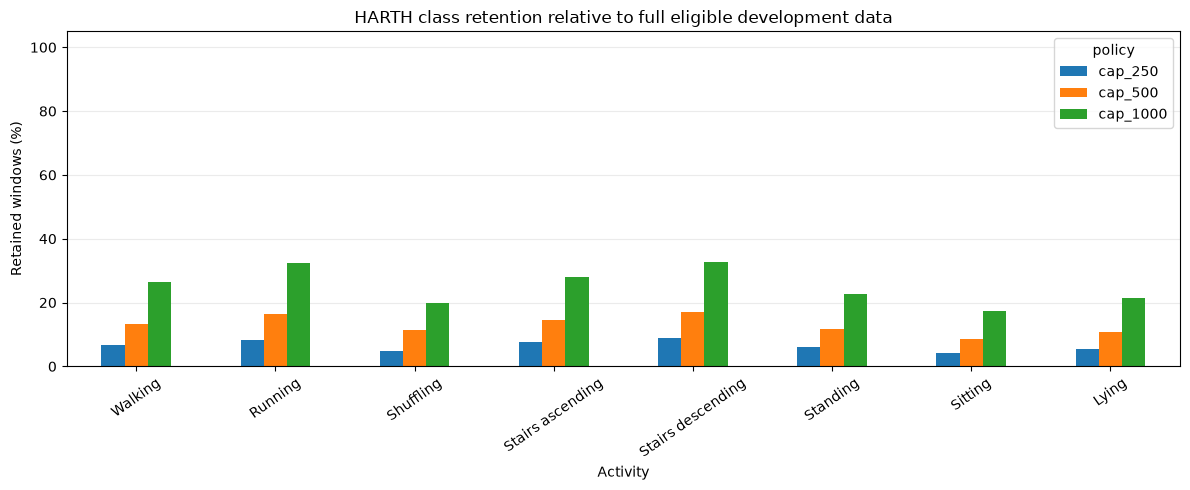

In [4]:
# =============== 04. Compare Class Retention Against Full Data ===============

# --------- 1. Align each activity count across four source policies. ---------
counts = class_counts.pivot(index="label", columns="policy", values="windows"
                           ).reindex(index=TASK_CLASSES, columns=policies)

# -------- 2. Calculate class retention relative to all eligible rows. --------
retention = counts.div(counts["full"], axis=0).mul(100)

# ----------- 3. Use documented activity names for the audit table. -----------
retention.index = [ACTIVITY_NAMES[k] for k in TASK_CLASSES]

# -------- 4. Display the saved activity-level retention percentages. ---------
display(retention.round(2))

# --------- 5. Compare label-blind cap retention using grouped bars. ----------
ax = retention[["cap_250", "cap_500", "cap_1000"]].plot(
    kind="bar", figsize=(12, 5), rot=35)
ax.set(title="HARTH class retention relative to full eligible development data",
       xlabel="Activity", ylabel="Retained windows (%)", ylim=(0, 105))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**05. Audit Independent Participant Support**

Count participants contributing windows to each activity under the full and capped policies. Many windows from a few participants do not provide broad participant-level coverage.

policy,full,cap_250,cap_500,cap_1000
Walking,29,29,29,29
Running,19,19,19,19
Shuffling,28,22,26,27
Stairs ascending,26,24,24,25
Stairs descending,25,22,25,25
Standing,29,29,29,29
Sitting,28,28,28,28
Lying,23,23,23,23


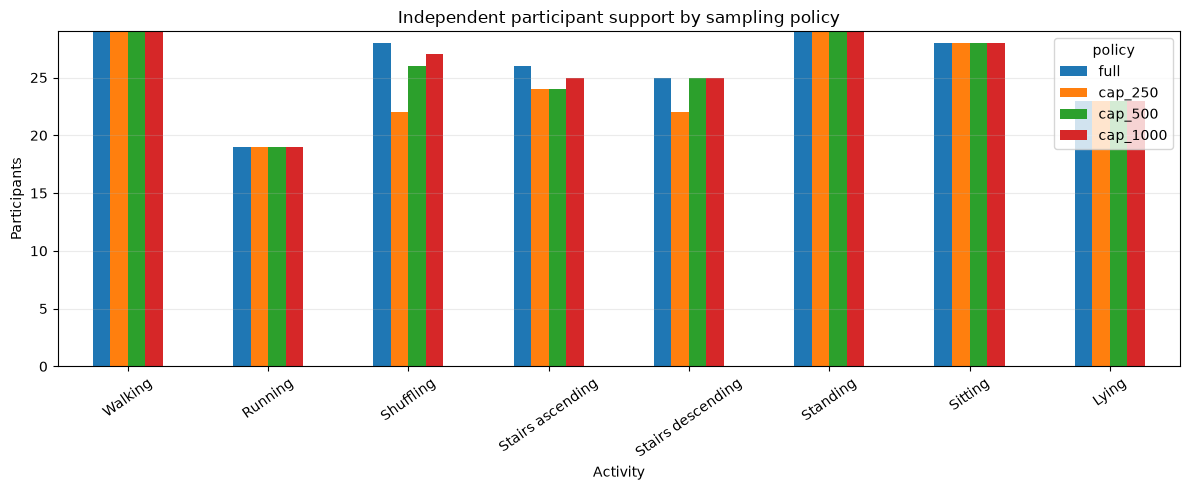

In [5]:
# ============== 05. Check Independent Participant Class Support ==============

# ------------ 1. Count people with at least one window per class. ------------
support = (
    selected.groupby(["policy", "label"])["subject_id"].nunique()
    .rename("subjects").reset_index()
    .pivot(index="label", columns="policy", values="subjects")
    .reindex(index=TASK_CLASSES, columns=policies).fillna(0).astype(int)
)

# --------- 2. Label each documented activity across source policies. ---------
support.index = [ACTIVITY_NAMES[k] for k in TASK_CLASSES]

# ----------- 3. Show participant coverage for every sampling cap. ------------
display(support)

# -------- 4. Compare independent-person support rather than windows. ---------
ax = support.plot(kind="bar", figsize=(12, 5), rot=35)
ax.set(title="Independent participant support by sampling policy",
       xlabel="Activity", ylabel="Participants", ylim=(0, 29))
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**06. Examine Minority-Class Coverage by Participant**

Inspect Shuffling and both stair activities. Under the 500-window cap, Shuffling was retained for 26 of 28 originally contributing participants; Stairs ascending remained for 24 of 26. Report participants who lose all retained windows for an activity.

In [6]:
# ============== 06. Inspect Minority-Activity Subject Coverage ===============

# -------------- 1. Select Shuffling and both stair activities. ---------------
focus_codes = [3, 4, 5]

# ---------- 2. Restrict the audit to original source rows for them. ----------
minority = selected.loc[selected["label"].isin(focus_codes)]

# ----------- 3. Cross-tabulate subject, class and sampling policy. -----------
detail = pd.crosstab(
    index=[minority["subject_id"], minority["label"]],
    columns=minority["policy"],
).reindex(columns=policies, fill_value=0)

# ------------ 4. Report sample loss for each relevant individual. ------------
display(detail)

# ---------- 5. Confirm no activity-based sample selection was used. ----------
print("Source windows are sampled chronologically; no label balancing was applied.")

policy            full  cap_250  cap_500  cap_1000
subject_id label                                  
S006       3        59        2        4         8
           4        19        1        2         3
           5        26        2        3         4
S008       3       259        8       22        33
           4        10        1        0         1
...                ...      ...      ...       ...
S037       4        28        2        4         9
           5        62        6       10        20
S038       3         3        1        1         2
           4        69        6       11        23
           5        45        4        7        13

[79 rows x 4 columns]

Source windows are sampled chronologically; no label balancing was applied.


**07. Sampling Quality Gate and Interpretation**

Check source-window totals, class retention and excluded Test identities. The audit identifies changes in available training evidence; the effect of a larger Train cap on Validation Macro F1 was subsequently examined in the matched nested-training experiments of Notebooks 15–17; this sampling audit does not itself estimate model performance.

In [7]:
# ============= 07. Sampling Sensitivity Scientific Quality Gate ==============

# ------------- 1. Require all 29 Development source identities. --------------
assert set(selected["subject_id"]) == set(DEVELOPMENT_SUBJECTS)

# ----------- 2. Exclude both original reserved Test participants. ------------
assert not (set(selected["subject_id"]) & RESERVED_TEST)

# ------------ 3. Reconcile the full-policy original window count. ------------
assert len(selected.loc[selected["policy"] == "full"]) == len(metadata)

# -------------- 4. Verify Stage 10-style 500-cap row selection. --------------
assert int(per_subject.loc[per_subject.policy == "cap_500", "windows"].sum()) == 14201

# ---------- 5. Require each class retention to remain at most 100%. ----------
assert all((retention <= 100 + 1e-8).to_numpy().ravel())

# ----------- 6. Reconcile the full class histogram with metadata. ------------
assert class_counts.groupby("policy")["windows"].sum().loc["full"] == len(metadata)

# ------------- 7. Report source audit completion and integrity. --------------
print("Chronological sampling sensitivity audit: PASSED")

# -------------- 8. Confirm final Test was excluded throughout. ---------------
print("Reserved original Test loaded/scored: NO")

# ----------- 9. State clearly that no predictive model was fitted. -----------
print("Models fitted in Stage 14: NONE")

Chronological sampling sensitivity audit: PASSED
Reserved original Test loaded/scored: NO
Models fitted in Stage 14: NONE
